# 02 · EDA: séries, averiguação, marcos de temporada e janela de imunização

Lê só `data/processed/` (saídas de `01_dados_srag_vsr.ipynb`). Critério principal: UF de residência, faixa `00-23m`. Alvo principal `vsr`; sensibilidade `srag`; `vsr_est_inf`/`vsr_est_sup` só como faixa.

**Saídas** (contrato com a modelagem): `data/processed/eda_marcos_temporada.parquet` — início, pico, fim, janela mínima de 90% e fração em fev–ago por unidade × temporada × série. Definições em `vsr_comum.py` e `docs/METODOLOGIA.md` §6.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vsr_comum import (P, carregar_painel, fracao_na_janela, inicio_fim_limiar, janela_minima,
                       marcos_temporada, mem_limiar, metadados, verificar_ambiente)
import vsr_nowcast as vn

verificar_ambiente()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

META = metadados()
REFS = META["temporadas_referencia"]
PAINEL = carregar_painel()
TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")
REGIOES = ["NORTE", "NORDESTE", "CENTRO_OESTE", "SUDESTE", "SUL"]
REGIAO_UF = TIERS["regiao"].to_dict()
print("corte:", META["data_corte"], "| última semana:", META["semana_final_painel"], "| referências:", REFS)

corte: 2026-10-18 | última semana: 2026-10-11 | referências: [2019, 2022, 2023, 2024, 2025]


## 1. Séries semanais: Brasil e regiões

`vsr` (linha), faixa [`vsr_est_inf`, `vsr_est_sup`] (sombreado) e `srag` (tracejado), escala log. Sombreado cinza: `quebra_npi`; linha vertical: início da imunização.

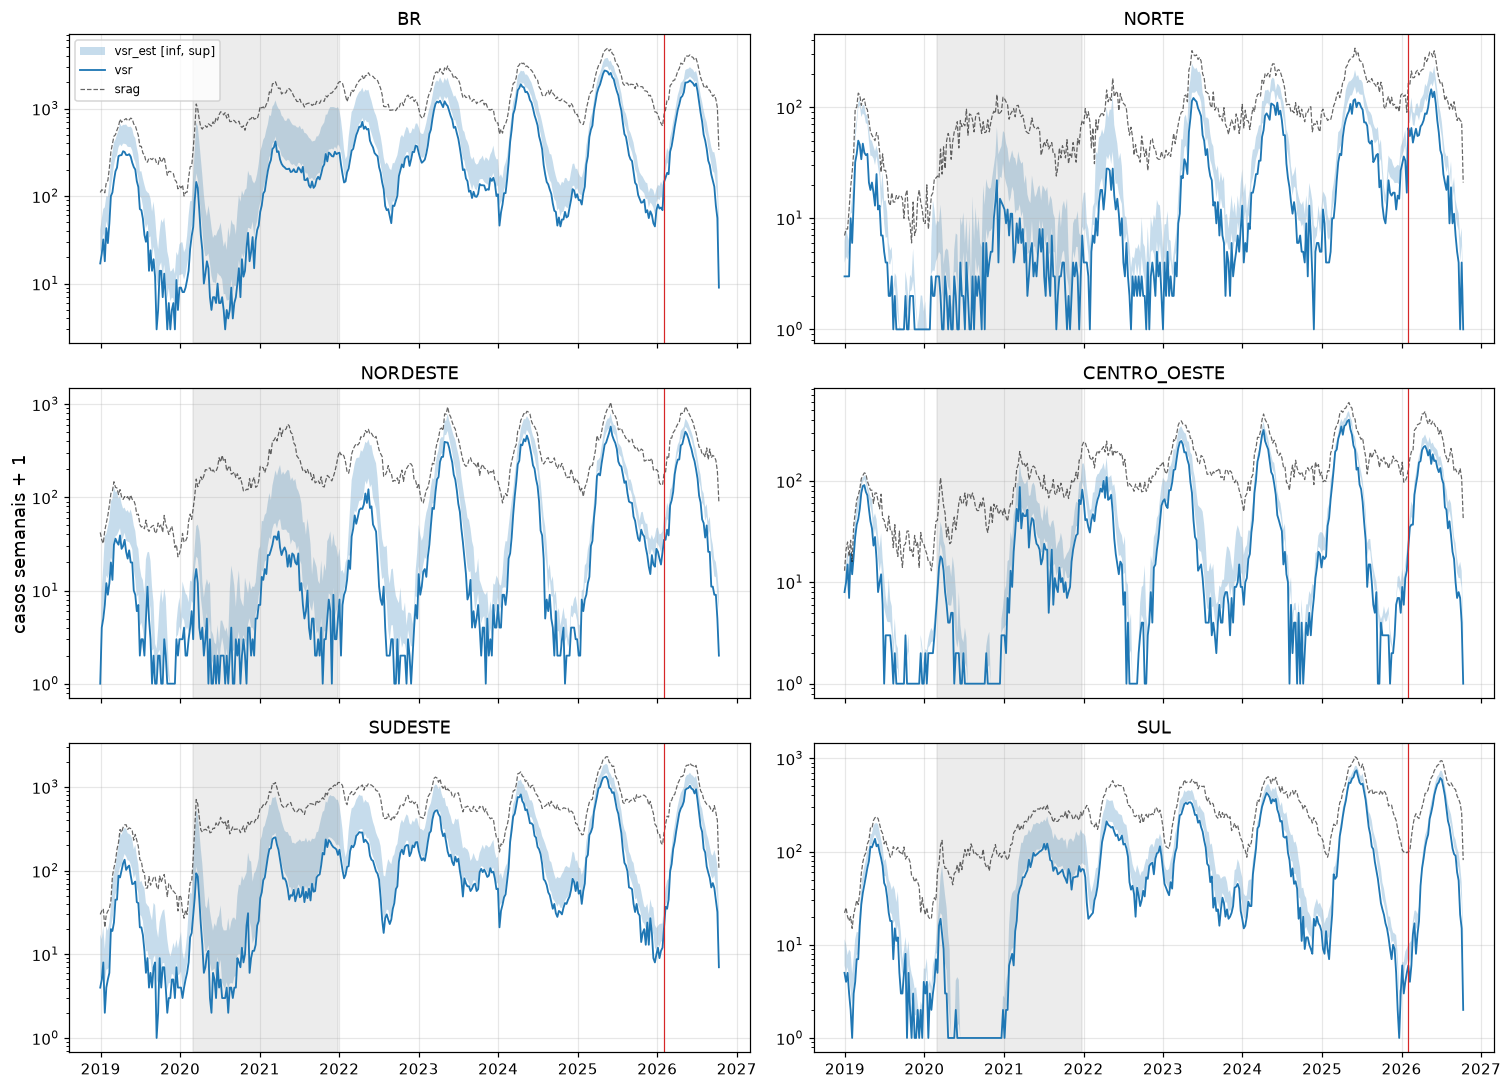

In [2]:
agg = PAINEL.loc[PAINEL["nivel"] != "UF"]
fig, axs = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, u in zip(axs.flat, ["BR"] + REGIOES):
    g = agg.loc[agg["unidade"] == u].sort_values("semana")
    ax.fill_between(g["semana"], g["vsr_est_inf"] + 1, g["vsr_est_sup"] + 1, alpha=0.25, label="vsr_est [inf, sup]")
    ax.plot(g["semana"], g["vsr"] + 1, lw=1.2, label="vsr")
    ax.plot(g["semana"], g["srag"] + 1, lw=0.8, ls="--", color="k", alpha=0.6, label="srag")
    q = g.loc[g["quebra_npi"], "semana"]
    ax.axvspan(q.min(), q.max(), color="grey", alpha=0.15)
    ax.axvline(pd.Timestamp(META["config"]["imunizacao_ini"]), color="tab:red", lw=0.8)
    ax.set_yscale("log"); ax.set_title(u)
axs[0, 0].legend(loc="upper left", fontsize=8)
fig.supylabel("casos semanais + 1"); fig.tight_layout()

## 2. Averiguação não estacionária

Fração da SRAG com resultado laboratorial e fração confirmada para VSR, por UF e ano. O crescimento da testagem desloca o nível das séries; por isso os marcos de temporada (§3) são definidos de forma relativa ao total de cada temporada.

In [3]:
uf = PAINEL.loc[PAINEL["nivel"] == "UF"]
anual = uf.groupby(["unidade", "ano_epi"])[["srag", "vsr", "lab_resultado"]].sum()
FRAC_LAB = (anual["lab_resultado"] / anual["srag"]).unstack().round(2)
FRAC_VSR = (anual["vsr"] / anual["srag"]).unstack().round(2)
print("Fração com resultado laboratorial"); display(FRAC_LAB)
print("vsr / srag"); display(FRAC_VSR)

Fração com resultado laboratorial


ano_epi,2019,2020,2021,2022,2023,2024,2025,2026
unidade,,,,,,,,
AC,0.81,0.82,0.67,0.78,0.73,0.76,0.82,0.81
AL,0.85,0.68,0.49,0.77,0.88,0.87,0.87,0.70
AM,0.54,0.59,0.71,0.88,0.84,0.78,0.80,0.68
AP,0.68,0.40,0.42,0.48,0.84,0.80,0.89,0.85
BA,0.86,0.88,0.89,0.88,0.91,0.94,0.94,0.94
CE,0.91,0.78,0.64,0.58,0.83,0.84,0.91,0.88
DF,0.78,0.85,0.95,0.96,0.97,0.99,0.99,0.99
ES,0.81,0.78,0.66,0.91,0.92,0.97,0.96,0.96
GO,0.94,0.95,0.95,0.94,0.96,0.96,0.96,0.94


vsr / srag


ano_epi,2019,2020,2021,2022,2023,2024,2025,2026
unidade,,,,,,,,
AC,0.31,0.00,0.00,0.15,0.23,0.27,0.30,0.29
AL,0.04,0.00,0.01,0.04,0.12,0.37,0.37,0.30
AM,0.34,0.11,0.12,0.13,0.26,0.33,0.30,0.24
AP,0.16,0.03,0.06,0.05,0.26,0.25,0.32,0.34
BA,0.23,0.03,0.14,0.18,0.25,0.39,0.38,0.42
CE,0.14,0.03,0.03,0.08,0.32,0.24,0.40,0.27
DF,0.38,0.05,0.30,0.24,0.35,0.38,0.39,0.38
ES,0.31,0.07,0.14,0.31,0.32,0.37,0.40,0.47
GO,0.47,0.06,0.23,0.22,0.29,0.35,0.39,0.34


## 3. Marcos da temporada (definição *a priori*)

Para cada unidade × temporada × série, com $y_k$ na semana da temporada $k$ e $C_k = \sum_{j \le k} y_j / \sum_j y_j$ (constantes em `vsr_comum.py`):

- início $= \min\{k: C_k \ge 0{,}10\}$, fim $= \min\{k: C_k \ge 0{,}90\}$;
- pico $= \arg\max_k \bar y_k$, com $\bar y$ a média móvel centrada de 3 semanas;
- janela mínima: menor intervalo contíguo com ≥ 90% dos casos;
- fração em fev–ago: casos com semana de sintomas (mês da quarta-feira) entre fevereiro e agosto.

`completa = False` para temporadas com menos de 52 semanas ou sem cobertura total (2026 está em curso: marcos relativos ao observado até o corte). `referencia` = temporada usada na climatologia.

In [4]:
def tabela_marcos(painel: pd.DataFrame, serie: str) -> pd.DataFrame:
    linhas = []
    for (nivel, unidade, temp), g in painel.groupby(["nivel", "unidade", "temporada"]):
        g = g.sort_values("semana_temporada")
        y = g.set_index("semana_temporada")[serie]
        data = g.set_index("semana_temporada")["semana"]
        m, j = marcos_temporada(y), janela_minima(y)
        linhas.append({"nivel": nivel, "unidade": unidade, "temporada": int(temp), "serie": serie,
                       "semanas": len(g), "completa": len(g) >= 52 and bool(g["coberta"].all()), **m, **j,
                       "pico_data": data.get(m["pico"]), "inicio_data": data.get(m["inicio"]),
                       "frac_fev_ago": fracao_na_janela(g["semana"], g[serie])})
    out = pd.DataFrame(linhas)
    out["referencia"] = out["temporada"].isin(REFS)
    out["regiao"] = np.where(out["nivel"] == "UF", out["unidade"].map(REGIAO_UF),
                             np.where(out["nivel"] == "REGIAO", out["unidade"], "BR"))
    out["tier"] = out["unidade"].map(TIERS["tier"])
    return out


# semanas ainda incompletas (o − 26 … o) do vsr: mediana do nowcast gamma_rw na última semana do painel (§6.1)
A, SEM = vn.cubo()
NC, _ = vn.nowcast_padrao(A, SEM, SEM[-1], np.random.default_rng(20261019))
nc = pd.DataFrame(np.median(NC, 2).T, index=SEM[-vn.D - 1:], columns=vn.ORDEM).stack().rename("nc")
PAINEL_M = PAINEL.join(nc, on=["semana", "unidade"])
PAINEL_M["vsr"] = PAINEL_M["nc"].fillna(PAINEL_M["vsr"])
TEMP_NC = PAINEL_M.loc[PAINEL_M["nc"].notna(), "temporada"].unique()
MARCOS = pd.concat([tabela_marcos(PAINEL_M, "vsr"), tabela_marcos(PAINEL, "srag")], ignore_index=True)
MARCOS["nowcast_aplicado"] = (MARCOS["serie"] == "vsr") & MARCOS["temporada"].isin(TEMP_NC)

# definições alternativas (§10.3), vsr, temporadas 2022+: MEM com limiar das outras temporadas completas 2022–2025
# e limiar de taxa único = mediana da taxa por 100 mil na semana de início a priori (UF-temporadas 2023–2025)
pm = PAINEL_M.loc[PAINEL_M["temporada"] >= 2022]
CURV = {k: g.sort_values("semana_temporada")["vsr"].to_numpy(float) for k, g in pm.groupby(["unidade", "temporada"])}
TAXA = {k: g.sort_values("semana_temporada")["vsr_taxa100k"].to_numpy(float) for k, g in pm.groupby(["unidade", "temporada"])}
ini_ap = MARCOS.query("serie == 'vsr' and nivel == 'UF' and completa and 2023 <= temporada <= 2025")
LIMIAR_TAXA = float(np.nanmedian([TAXA[u, t][int(i) - 1] for u, t, i in ini_ap[["unidade", "temporada", "inicio"]].to_numpy()]))
alt = []
for (u, t), y in CURV.items():
    outras = [CURV[u, x] for x in range(2022, 2026) if x != t and (u, x) in CURV]
    lim = mem_limiar(outras)
    im, fm = inicio_fim_limiar(y, lim)
    it, ft = inicio_fim_limiar(TAXA[u, t], LIMIAR_TAXA)
    alt.append({"unidade": u, "temporada": t, "serie": "vsr", "limiar_mem": lim, "inicio_mem": im, "fim_mem": fm,
                "inicio_taxa": it, "fim_taxa": ft})
MARCOS = MARCOS.merge(pd.DataFrame(alt), on=["unidade", "temporada", "serie"], how="left")
MARCOS.to_parquet(P / "eda_marcos_temporada.parquet", index=False)
print(f"limiar de taxa: {LIMIAR_TAXA:.2f} casos/100 mil/semana; nowcast aplicado nas temporadas {sorted(TEMP_NC)}")
reg = MARCOS.query("serie == 'vsr' and nivel != 'UF'")
for c in ("inicio", "pico", "fim"):
    print(f"{c} (semana da temporada), vsr"); display(reg.pivot(index="unidade", columns="temporada", values=c)
                                                     .reindex(["BR"] + REGIOES))

limiar de taxa: 17.62 casos/100 mil/semana; nowcast aplicado nas temporadas [np.int64(2026)]
inicio (semana da temporada), vsr


temporada,2019,2020,2021,2022,2023,2024,2025,2026
unidade,,,,,,,,
BR,10.0,9.0,8.0,8.0,8.0,11.0,13.0,13.0
NORTE,8.0,18.0,3.0,10.0,16.0,13.0,15.0,6.0
NORDESTE,8.0,7.0,6.0,10.0,12.0,14.0,16.0,12.0
CENTRO_OESTE,8.0,10.0,9.0,4.0,5.0,10.0,10.0,11.0
SUDESTE,12.0,10.0,7.0,7.0,6.0,11.0,12.0,14.0
SUL,15.0,5.0,15.0,12.0,11.0,12.0,16.0,19.0


pico (semana da temporada), vsr


temporada,2019,2020,2021,2022,2023,2024,2025,2026
unidade,,,,,,,,
BR,17.0,12.0,10.0,15.0,14.0,17.0,20.0,22.0
NORTE,10.0,48.0,2.0,17.0,21.0,21.0,23.0,21.0
NORDESTE,13.0,12.0,12.0,19.0,19.0,19.0,23.0,19.0
CENTRO_OESTE,14.0,12.0,52.0,15.0,13.0,15.0,18.0,16.0
SUDESTE,17.0,12.0,10.0,15.0,12.0,15.0,19.0,21.0
SUL,21.0,12.0,28.0,17.0,19.0,17.0,24.0,26.0


fim (semana da temporada), vsr


temporada,2019,2020,2021,2022,2023,2024,2025,2026
unidade,,,,,,,,
BR,26.0,51.0,49.0,48.0,33.0,29.0,30.0,29.0
NORTE,22.0,52.0,43.0,30.0,32.0,30.0,39.0,26.0
NORDESTE,24.0,51.0,31.0,24.0,26.0,26.0,35.0,27.0
CENTRO_OESTE,21.0,20.0,51.0,48.0,20.0,24.0,25.0,28.0
SUDESTE,26.0,50.0,49.0,49.0,43.0,30.0,28.0,29.0
SUL,28.0,14.0,47.0,48.0,32.0,30.0,31.0,32.0


posto do início (1 = mais cedo)


unidade,CENTRO_OESTE,NORDESTE,NORTE,SUDESTE,SUL
temporada,,,,,
2019,2.0,2.0,2.0,4.0,5.0
2020,3.5,2.0,5.0,3.5,1.0
2021,4.0,2.0,1.0,3.0,5.0
2022,1.0,3.5,3.5,2.0,5.0
2023,1.0,4.0,5.0,2.0,3.0
2024,1.0,5.0,4.0,2.0,3.0
2025,1.0,4.5,3.0,2.0,4.5
2026,2.0,3.0,1.0,4.0,5.0


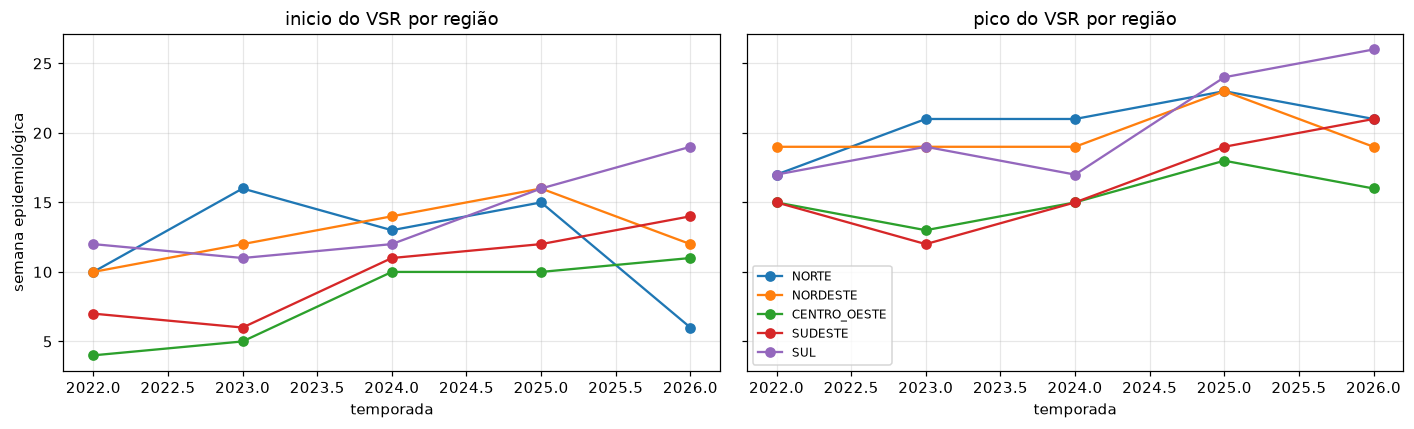

In [5]:
# Ordem regional de início e pico nas temporadas comparáveis (2023 em diante)
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, c in zip(axs, ("inicio", "pico")):
    for r in REGIOES:
        g = reg.loc[(reg["unidade"] == r) & (reg["temporada"] >= 2022)]
        ax.plot(g["temporada"], g[c], marker="o", label=r)
    ax.set_title(f"{c} do VSR por região"); ax.set_xlabel("temporada")
axs[0].set_ylabel("semana epidemiológica"); axs[1].legend(fontsize=8)
fig.tight_layout()
ORDEM = reg.loc[reg["nivel"] == "REGIAO"].pivot(index="temporada", columns="unidade", values="inicio").rank(axis=1)
print("posto do início (1 = mais cedo)"); display(ORDEM)

In [6]:
# Concordância entre alvos: diferença de pico vsr − srag (semanas), por nível
dif = MARCOS.pivot_table(index=["nivel", "unidade", "temporada"], columns="serie", values="pico")
dif = (dif["vsr"] - dif["srag"]).rename("pico_vsr_menos_srag").reset_index()
display(dif.loc[dif["temporada"] >= 2022].groupby("nivel")["pico_vsr_menos_srag"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
nivel,,,,,,,,
BRASIL,5.0,-1.8,2.9,-5.0,-5.0,0.0,0.0,1.0
REGIAO,25.0,0.5,4.2,-4.0,-1.0,0.0,0.0,14.0
UF,135.0,0.4,6.0,-10.0,-1.0,0.0,0.0,51.0


## 4. Janela de imunização (viabilidade de H4)

Fração do VSR dentro da janela nacional fixa (fev–ago) e duração da janela mínima com 90% dos casos, por UF e temporada. Se a fração fixa já passa de 0,9 em quase todas, H4 é argumento de custo (janela regional mais curta com a mesma cobertura), não de cobertura.

In [7]:
ufs = MARCOS.query("serie == 'vsr' and nivel == 'UF' and completa and temporada >= 2022")
FEV_AGO = ufs.pivot(index="unidade", columns="temporada", values="frac_fev_ago").round(2)
display(FEV_AGO)
print(f"pares UF-temporada com ≥ 90% em fev–ago: {(FEV_AGO >= 0.9).to_numpy().mean():.0%}")
DUR = ufs.pivot(index="unidade", columns="temporada", values="janela_dur")
print("duração (semanas) da janela mínima com 90% — fev–ago tem ~30 semanas"); display(DUR)

temporada,2022,2023,2024,2025
unidade,,,,
AC,0.93,0.98,0.93,0.86
AL,0.94,0.86,0.99,0.91
AM,0.95,0.98,0.93,0.56
AP,0.90,0.98,0.94,0.99
BA,0.95,0.96,0.98,0.91
CE,0.98,0.99,0.99,1.00
DF,0.68,0.82,0.95,0.97
ES,0.81,0.85,0.96,0.97
GO,0.74,0.89,0.93,0.96


pares UF-temporada com ≥ 90% em fev–ago: 71%
duração (semanas) da janela mínima com 90% — fev–ago tem ~30 semanas


temporada,2022,2023,2024,2025
unidade,,,,
AC,20.0,18.0,19.0,38.0
AL,14.0,26.0,14.0,20.0
AM,21.0,19.0,18.0,32.0
AP,17.0,14.0,19.0,18.0
BA,20.0,19.0,16.0,23.0
CE,19.0,17.0,14.0,14.0
DF,49.0,20.0,15.0,17.0
ES,45.0,27.0,19.0,20.0
GO,38.0,21.0,19.0,19.0


## 5. Tiers e esparsidade

Tiers fixados *a priori* no notebook 01 (mínimo de VSR em 2023–2025: ≥ 300 ⇒ A, ≥ 100 ⇒ B). Fração de semanas com zero VSR em 2023–2025 e variabilidade do pico entre temporadas.

In [8]:
z = uf.loc[uf["ano_epi"].isin([2023, 2024, 2025])].groupby("unidade")["vsr"].apply(lambda s: (s == 0).mean())
var_pico = MARCOS.query("serie == 'vsr' and nivel == 'UF' and completa and temporada >= 2022").groupby(
    "unidade")["pico"].agg(["min", "max", "std"])
display(TIERS[["regiao", "tier", "min_temporadas_tier"]].join(z.rename("frac_semanas_zero").round(2))
        .join(var_pico.round(1)).sort_values(["tier", "min_temporadas_tier"], ascending=[True, False]))

,regiao,tier,min_temporadas_tier,frac_semanas_zero,min,max,std
unidade,,,,,,,
SP,SUDESTE,A,6041.0,0.00,12.0,45.0,15.2
PR,SUL,A,2091.0,0.02,15.0,24.0,4.0
RS,SUL,A,1957.0,0.03,20.0,26.0,2.5
SC,SUL,A,1913.0,0.03,17.0,27.0,4.4
MG,SUDESTE,A,1356.0,0.06,11.0,52.0,18.7
DF,CENTRO_OESTE,A,1210.0,0.15,12.0,15.0,1.3
BA,NORDESTE,A,970.0,0.10,14.0,24.0,4.2
CE,NORDESTE,A,843.0,0.37,18.0,24.0,2.6
RJ,SUDESTE,A,806.0,0.06,14.0,21.0,3.0


## 6. Atraso de notificação: completude $F_r(d)$

atraso                 0     1     2     3     4     5     6     7     8
serie regiao                                                            
srag  BR            0.18  0.65  0.80  0.87  0.91  0.93  0.95  0.96  0.96
      CENTRO_OESTE  0.17  0.67  0.85  0.91  0.94  0.95  0.97  0.97  0.98
      NORDESTE      0.22  0.69  0.83  0.89  0.92  0.94  0.96  0.96  0.97
      NORTE         0.20  0.67  0.82  0.88  0.92  0.94  0.95  0.96  0.97
      SUDESTE       0.15  0.59  0.76  0.84  0.89  0.92  0.94  0.95  0.96
      SUL           0.21  0.71  0.84  0.89  0.92  0.93  0.95  0.95  0.96
vsr   BR            0.09  0.57  0.79  0.87  0.91  0.94  0.95  0.96  0.97
      CENTRO_OESTE  0.10  0.63  0.84  0.90  0.92  0.94  0.96  0.97  0.98
      NORDESTE      0.11  0.58  0.79  0.88  0.92  0.94  0.96  0.97  0.97
      NORTE         0.07  0.59  0.82  0.90  0.94  0.95  0.97  0.98  0.98
      SUDESTE       0.09  0.52  0.75  0.84  0.89  0.92  0.94  0.95  0.96
      SUL           0.10  0.62  0.84  0.91  0.93  0.95  0.96  0.96  0.97

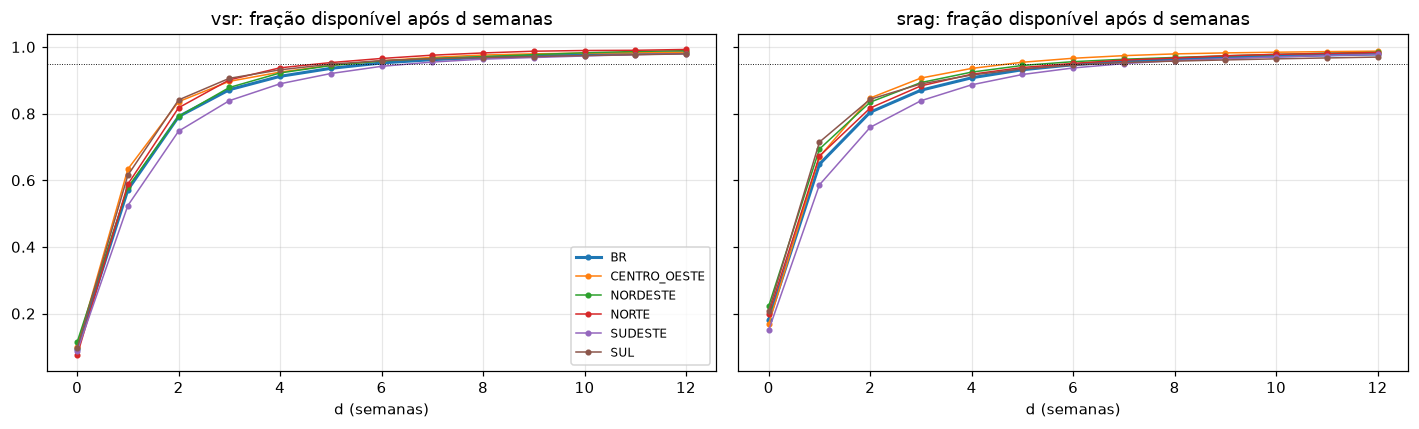

In [9]:
comp = pd.read_parquet(P / "completude_atraso.parquet")
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, s in zip(axs, ("vsr", "srag")):
    for r, g in comp.loc[(comp["serie"] == s) & (comp["atraso"] <= 12)].groupby("regiao"):
        ax.plot(g["atraso"], g["F"], marker=".", lw=2 if r == "BR" else 1, label=r)
    ax.axhline(META["config"]["completude_flag"], color="k", lw=0.6, ls=":")
    ax.set_title(f"{s}: fração disponível após d semanas"); ax.set_xlabel("d (semanas)")
axs[0].legend(fontsize=8); fig.tight_layout()
display(comp.pivot_table(index=["serie", "regiao"], columns="atraso", values="F").iloc[:, :9].round(2))

## 7. 2026 (primeira temporada com imunização) contra a climatologia

Climatologia `expanding` para a temporada-alvo 2026 (só temporadas anteriores): $\exp(\overline{\log(1+y)}) - 1$ ± 1 dp em escala log. Semanas recentes de 2026 ainda incompletas (`semana_incompleta`) em vermelho.

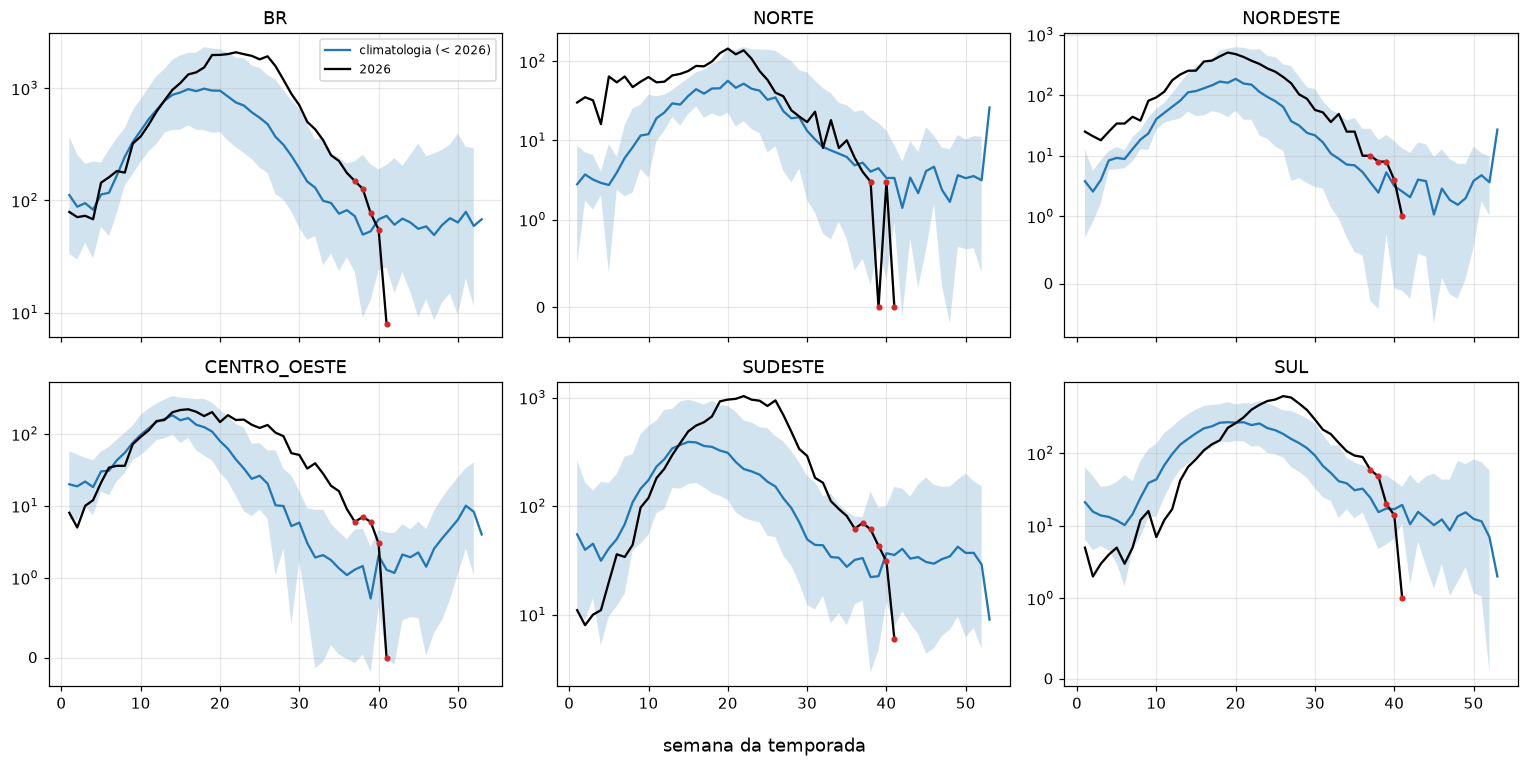

In [10]:
clim = pd.read_parquet(P / "climatologia.parquet", filters=[
    ("criterio_uf", "==", "residencia"), ("faixa_etaria", "==", "00-23m"), ("serie", "==", "vsr"),
    ("tipo", "==", "expanding"), ("temporada_alvo", "==", 2026)])
fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, u in zip(axs.flat, ["BR"] + REGIOES):
    c = clim.loc[clim["unidade"] == u].sort_values("semana_temporada")
    ax.fill_between(c["semana_temporada"], np.expm1(c["media_log1p"] - c["dp_log1p"]),
                    np.expm1(c["media_log1p"] + c["dp_log1p"]), alpha=0.2)
    ax.plot(c["semana_temporada"], np.expm1(c["media_log1p"]), label="climatologia (< 2026)")
    g = PAINEL.loc[(PAINEL["unidade"] == u) & (PAINEL["temporada"] == 2026)].sort_values("semana_temporada")
    ax.plot(g["semana_temporada"], g["vsr"], color="k", label="2026")
    inc = g.loc[g["semana_incompleta"]]
    ax.plot(inc["semana_temporada"], inc["vsr"], "o", color="tab:red", ms=3)
    ax.set_yscale("symlog", linthresh=1); ax.set_title(u)
axs[0, 0].legend(fontsize=8); fig.supxlabel("semana da temporada"); fig.tight_layout()

## 7b. Sensibilidade das definições de início e fim (MEM e limiar de taxa)

Diferença (semanas) entre as definições alternativas e a *a priori* (fração acumulada 0,10/0,90), temporadas 2022–2026 do `vsr`:
- **MEM** (Vega et al., 2013; `vsr_comum.mem_limiar`): período epidêmico pelo critério de inclinação de 2,8%; limiar pré-epidêmico = limite superior do IC 95% unilateral da média geométrica dos maiores valores pré-epidêmicos das **outras** temporadas completas de 2022–2025; início/fim = 1ª/última semana ≥ limiar.
- **Taxa:** 1ª/última semana com taxa ≥ limiar único (mediana da taxa por 100 mil na semana de início *a priori*, UF-temporadas 2023–2025).

In [11]:
v = MARCOS.query("serie == 'vsr' and temporada >= 2022").copy()
for alt in ("mem", "taxa"):
    for m in ("inicio", "fim"):
        v[f"d_{m}_{alt}"] = v[f"{m}_{alt}"] - v[m]
cols = [c for c in v if c.startswith("d_")]
resumo = v.groupby("nivel")[cols].agg(lambda x: x.abs().median()).round(1)
print("mediana |diferença| (semanas)"); display(resumo)
print("fração a ±2 semanas da definição a priori"); display(v.groupby("nivel")[cols].agg(lambda x: (x.abs() <= 2).mean()).round(2))
print("sem início pela definição (limiar nunca atingido)"); display(v.groupby("nivel")[["inicio_mem", "inicio_taxa"]].agg(lambda x: x.isna().mean()).round(2))
display(v.query("nivel != 'UF'").pivot_table(index="unidade", columns="temporada", values=["inicio", "inicio_mem", "inicio_taxa"]))

mediana |diferença| (semanas)


,d_inicio_mem,d_fim_mem,d_inicio_taxa,d_fim_taxa
nivel,,,,
BRASIL,3.0,4.0,1.0,2.5
REGIAO,4.0,4.0,2.0,3.0
UF,4.0,4.0,1.0,2.0


fração a ±2 semanas da definição a priori


,d_inicio_mem,d_fim_mem,d_inicio_taxa,d_fim_taxa
nivel,,,,
BRASIL,0.40,0.20,0.60,0.4
REGIAO,0.16,0.28,0.56,0.4
UF,0.30,0.29,0.59,0.4


sem início pela definição (limiar nunca atingido)


,inicio_mem,inicio_taxa
nivel,,
BRASIL,0.00,0.20
REGIAO,0.00,0.12
UF,0.02,0.24


inicio                         inicio_mem                         inicio_taxa                        
temporada      2022  2023  2024  2025  2026       2022  2023  2024  2025  2026        2022  2023  2024  2025  2026
unidade                                                                                                           
BR              8.0   8.0  11.0  13.0  13.0        9.0   1.0   9.0   8.0  10.0         NaN  11.0  12.0  12.0  14.0
CENTRO_OESTE    4.0   5.0  10.0  10.0  11.0        1.0   1.0   9.0   7.0   9.0        12.0   5.0  10.0   8.0  10.0
NORDESTE       10.0  12.0  14.0  16.0  12.0       10.0   8.0  10.0  10.0   7.0         NaN  16.0  16.0  18.0  14.0
NORTE          10.0  16.0  13.0  15.0   6.0       16.0  13.0   7.0  10.0   1.0         NaN  20.0  20.0  20.0  18.0
SUDESTE         7.0   6.0  11.0  12.0  14.0        1.0   1.0   9.0   7.0  11.0         NaN  10.0  11.0  12.0  14.0
SUL            12.0  11.0  12.0  16.0  19.0        1.0   1.0   9.0   9.0  15.0        14.0  11.0  11.0  13.0  17.0

## 8. Resumo para a modelagem

In [12]:
ult = MARCOS.query("serie == 'vsr' and nivel == 'REGIAO' and completa and temporada >= 2023")
print("pico regional médio 2023+ (SE):", ult.groupby("unidade")["pico"].mean().round(1).sort_values().to_dict())
print("início regional médio 2023+ (SE):", ult.groupby("unidade")["inicio"].mean().round(1).sort_values().to_dict())
# temporada que cruza a virada do ano concentraria casos nas bordas do ano epidemiológico
bordas = PAINEL.loc[(PAINEL["nivel"] != "UF") & (PAINEL["temporada"].between(2022, 2025))].assign(
    borda=lambda d: (d["semana_temporada"] <= 4) | (d["semana_temporada"] >= 49))
bordas = bordas.groupby(["unidade", "temporada"]).apply(lambda g: g.loc[g["borda"], "vsr"].sum() / g["vsr"].sum())
print("máx. fração do VSR nas SE 1–4 e 49–53 (2022–2025):", bordas.groupby("unidade").max().round(2).to_dict())
print("UF-temporadas (2022+) com ≥ 90% em fev–ago:", f"{(FEV_AGO >= 0.9).to_numpy().mean():.0%}")
print("salvo:", P / "eda_marcos_temporada.parquet", MARCOS.shape)

pico regional médio 2023+ (SE): {'CENTRO_OESTE': 15.3, 'SUDESTE': 15.3, 'SUL': 20.0, 'NORDESTE': 20.3, 'NORTE': 21.7}
início regional médio 2023+ (SE): {'CENTRO_OESTE': 8.3, 'SUDESTE': 9.7, 'SUL': 13.0, 'NORDESTE': 14.0, 'NORTE': 14.7}
máx. fração do VSR nas SE 1–4 e 49–53 (2022–2025): {'BR': 0.15, 'CENTRO_OESTE': 0.21, 'NORDESTE': 0.03, 'NORTE': 0.06, 'SUDESTE': 0.18, 'SUL': 0.13}
UF-temporadas (2022+) com ≥ 90% em fev–ago: 71%
salvo: C:\MyCode\series_temporais\data\processed\eda_marcos_temporada.parquet (528, 25)
